In [47]:
!pip install pydicom


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [48]:
# ============================================================
# CONFIGURACIÓN GENERAL Y RUTA DE ACCESO UNIFICADA
# ============================================================
import os
import pydicom
import matplotlib.pyplot as plt
import numpy as np


Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 212
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: MR Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.840.113619.2.207.6945.297264.11272.1238998881.891
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.5.5
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_355'
(0002,0016) Source Application Entity Title     AE: 'BASIX'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'OTHER']
(0008,0016) SOP Class UID                       UI: MR Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.840.113619.2.207.6945.297264.11272.1238998

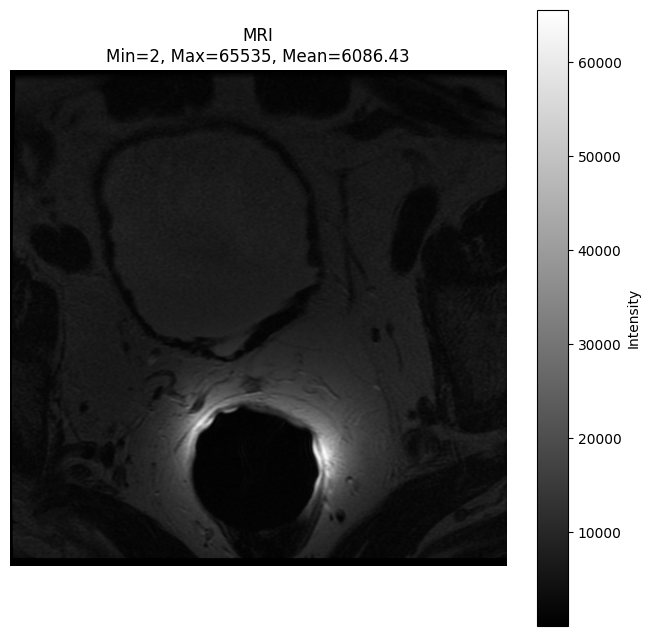

In [49]:
def process_dicom(path):
    """
    Lee un archivo DICOM, extrae e imprime sus metadatos principales,
    y genera estadísticas y visualizaciones básicas de la imagen.
    """
    dicom = pydicom.dcmread(path)
    print(dicom)
    print("\n========== DICOM HEADER ==========\n")

    fields = [
        "Modality", "Manufacturer", "ManufacturerModelName", "MagneticFieldStrength",
        "Rows", "Columns", "SamplesPerPixel", "PhotometricInterpretation",
        "BitsAllocated", "BitsStored", "HighBit", "PixelRepresentation",
        "PixelSpacing", "SliceThickness", "WindowCenter", "WindowWidth",
        "RescaleIntercept", "RescaleSlope", "AcquisitionMatrix",
        "RepetitionTime", "EchoTime", "FlipAngle", "InversionTime",
        "SequenceName", "ScanningSequence", "SequenceVariant", "PixelBandwidth"
    ]

    for field in fields:
        if hasattr(dicom, field):
            print(f"{field}: {getattr(dicom, field)}")

    pixel_array = dicom.pixel_array
    print("\n========== PIXEL ARRAY ==========\n")
    print("Shape:", pixel_array.shape)
    print("dtype:", pixel_array.dtype)
    print("Número de píxeles:", pixel_array.size)

    pixel_min, pixel_max = pixel_array.min(), pixel_array.max()
    pixel_mean, pixel_std = pixel_array.mean(), pixel_array.std()

    print("\n========== INTENSIDADES ==========\n")
    print("Mínimo:", pixel_min)
    print("Máximo:", pixel_max)
    print("Media:", pixel_mean)
    print("Desviación estándar:", pixel_std)

    print("\nPercentiles:")
    for p in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
        print(f"{p}%: {np.percentile(pixel_array, p)}")

    print("\n========== EJEMPLO DE PIXELES ==========\n")
    print(pixel_array[:10, :10])

    plt.figure(figsize=(8, 8))
    plt.imshow(pixel_array, cmap="gray")
    plt.colorbar(label="Intensity")
    plt.title(f"MRI\nMin={pixel_min}, Max={pixel_max}, Mean={pixel_mean:.2f}")
    plt.axis("off")
    plt.show()

# Ejecución de la inspección inicial usando el path unificado
process_dicom("imagenes/resonancia magentica/MRI01.dcm")

In [50]:
## Análisis del Ruido Residual en ROIs (Regiones de Interés)
## A continuación, definimos un conjunto de funciones modulares para evaluar de manera precisa las propiedades estadísticas del ruido en diferentes regiones de la imagen. Esto incluye el cálculo del **Factor de Fano (Índice de Dispersión)** sobre los valores crudos para caracterizar la naturaleza física del ruido (Poisson vs. Gaussiano).

In [51]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.stats import shapiro, skew, kurtosis, probplot

def cargar_dicom_hu(path):
    """Carga el DICOM y devuelve el dataset, la matriz en Unidades Hounsfield (HU) y los píxeles crudos."""
    ds = pydicom.dcmread(path)
    pixel_array_crudo = ds.pixel_array.astype(np.float64)
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    hu_array = pixel_array_crudo * slope + intercept
    return ds, hu_array, pixel_array_crudo

def extraer_roi(array_2d, centro, mitad_lado=15):
    """Extrae una sub-región cuadrada (ROI) de la imagen."""
    filas, columnas = array_2d.shape
    r0, c0 = centro
    r_ini, r_fin = r0 - mitad_lado, r0 + mitad_lado
    c_ini, c_fin = c0 - mitad_lado, c0 + mitad_lado
    if r_ini < 0 or c_ini < 0 or r_fin > filas or c_fin > columnas:
        raise ValueError(f"La ROI en {centro} excede los límites de la imagen (shape {array_2d.shape}).")
    return array_2d[r_ini:r_fin, c_ini:c_fin]

def extraer_ruido_residual(roi):
    """Resta la media para obtener las fluctuaciones puras del ruido: n(x,y) = I(x,y) - media(ROI)"""
    return roi - np.mean(roi)

def calcular_correlacion_espacial(ruido):
    """Calcula el coeficiente de correlación lineal con los píxeles vecinos adyacentes."""
    h1, h2 = ruido[:, :-1].flatten(), ruido[:, 1:].flatten()
    v1, v2 = ruido[:-1, :].flatten(), ruido[1:, :].flatten()
    corr_h = np.corrcoef(h1, h2)[0, 1] if len(h1) > 1 else 0.0
    corr_v = np.corrcoef(v1, v2)[0, 1] if len(v1) > 1 else 0.0
    return corr_h, corr_v

def calcular_indice_dispersion(roi_cruda):
    """Calcula el Factor de Fano (D = varianza / media) en píxeles crudos sin reescalar."""
    datos = roi_cruda.flatten()
    media = np.mean(datos)
    varianza = np.var(datos, ddof=1)
    D = varianza / media if media != 0 else 0.0
    return media, varianza, D

def analizar_ruido(roi_hu, roi_cruda, nombre="ROI"):
    """Compila todas las métricas de análisis estadístico de ruido en un diccionario."""
    ruido = extraer_ruido_residual(roi_hu)
    datos = ruido.flatten()

    media, std, varianza = np.mean(datos), np.std(datos, ddof=1), np.var(datos, ddof=1)
    asimetria, kurt = skew(datos), kurtosis(datos)
    shapiro_W, shapiro_p = shapiro(datos)

    z_scores = np.abs(datos / std) if std != 0 else np.zeros_like(datos)
    pct_3sigma = (np.sum(z_scores > 3) / len(datos)) * 100
    pct_4sigma = (np.sum(z_scores > 4) / len(datos)) * 100

    corr_h, corr_v = calcular_correlacion_espacial(ruido)
    media_cruda, var_cruda, fano_D = calcular_indice_dispersion(roi_cruda)

    resultados = {
        "nombre": nombre, "n": len(datos), "media_ruido": media, "std_ruido": std,
        "varianza_ruido": varianza, "skewness_ruido": asimetria, "kurtosis_ruido": kurt,
        "shapiro_W_ruido": shapiro_W, "shapiro_p_ruido": shapiro_p,
        "extremos_3sigma_pct": pct_3sigma, "extremos_4sigma_pct": pct_4sigma,
        "correlacion_horizontal": corr_h, "correlacion_vertical": corr_v,
        "media_cruda": media_cruda, "varianza_cruda": var_cruda, "fano_D": fano_D
    }
    return ruido, resultados

In [52]:
def imprimir_resultados_ruido(resultado):
    """Presenta las métricas de ruido de manera organizada en consola."""
    print("\n" + "=" * 75)
    print(f"ANÁLISIS DEL RUIDO RESIDUAL: {resultado['nombre']}")
    print("=" * 75)
    print(f"Número de píxeles:              {resultado['n']}")
    print(f"Media del ruido:                {resultado['media_ruido']:.6f} HU")
    print(f"Desviación estándar del ruido:  {resultado['std_ruido']:.4f} HU")
    print(f"Varianza del ruido:             {resultado['varianza_ruido']:.4f} HU²")

    print("\n---------- FORMA DE LA DISTRIBUCIÓN ----------")
    print(f"Skewness (Asimetría):           {resultado['skewness_ruido']:.4f}")
    print(f"Kurtosis (Fisher):              {resultado['kurtosis_ruido']:.4f}")

    print("\n---------- SHAPIRO-WILK ----------")
    print(f"W:                              {resultado['shapiro_W_ruido']:.4f}")
    print(f"p-value:                        {resultado['shapiro_p_ruido']:.5e}")
    if resultado["shapiro_p_ruido"] < 0.05:
        print("Resultado: Se rechaza la normalidad estricta del residuo (común con N grande).")
    else:
        print("Resultado: No se rechaza la normalidad del residuo.")

    print("\n---------- VALORES EXTREMOS ----------")
    print(f"|z| > 3σ:                       {resultado['extremos_3sigma_pct']:.2f}%")
    print(f"|z| > 4σ:                       {resultado['extremos_4sigma_pct']:.2f}%")

    print("\n---------- CORRELACIÓN ESPACIAL ----------")
    print(f"Horizontal:                     {resultado['correlacion_horizontal']:.4f}")
    print(f"Vertical:                       {resultado['correlacion_vertical']:.4f}")

    print("\n---------- ÍNDICE DE DISPERSIÓN (FACTOR DE FANO) ----------")
    print(f"Media (píxel crudo):            {resultado['media_cruda']:.4f}")
    print(f"Varianza (cruda):               {resultado['varianza_cruda']:.4f}")
    print(f"D = sigma^2 / mu:               {resultado['fano_D']:.6f}")

    D = resultado["fano_D"]
    if 0.8 <= D <= 1.2:
        print("Resultado: D ~ 1 -> Compatible con ruido tipo Poisson (cuántico puro).")
    elif D < 0.8:
        print("Resultado: D << 1 -> SE DESCARTA Poisson. Consistente con ruido GAUSSIANO de reconstrucción (FBP).")
    else:
        print("Resultado: D >> 1 -> Sobredispersión. La ROI podría no ser homogénea.")

def visualizar_roi_y_ruido(hu_array, roi, ruido, centro, nombre="ROI", mitad_lado=15, ventana_centro=40, ventana_ancho=100):
    """Genera los gráficos completos de análisis: imagen con ROI, histograma de intensidad, mapa 2D del ruido e histograma del ruido residual."""
    r0, c0 = centro
    r_ini, c_ini = r0 - mitad_lado, c0 - mitad_lado
    vmin = ventana_centro - ventana_ancho / 2
    vmax = ventana_centro + ventana_ancho / 2

    # Primer conjunto de gráficos: Localización de ROI e Histograma de Intensidad
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(hu_array, cmap="gray", vmin=vmin, vmax=vmax)
    rect = patches.Rectangle((c_ini, r_ini), mitad_lado*2, mitad_lado*2, linewidth=2, edgecolor="red", facecolor="none")
    axes[0].add_patch(rect)
    axes[0].set_title(f"{nombre} - Centro: {centro}")
    axes[0].axis("off")

    axes[1].hist(roi.flatten(), bins=30, edgecolor="black", color="steelblue", alpha=0.85)
    axes[1].axvline(np.mean(roi), linestyle="--", color="red", label=f"μ = {np.mean(roi):.2f} HU")
    axes[1].set_title(f"Histograma de Intensidad ({nombre})")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Segundo conjunto de gráficos: Mapa 2D de ruido residual y su histograma
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    limite = max(abs(np.min(ruido)), abs(np.max(ruido)))
    im = axes[0].imshow(ruido, cmap="gray", vmin=-limite, vmax=limite)
    axes[0].set_title(f"Mapa del ruido residual - {nombre}")
    axes[0].set_xlabel("Columna")
    axes[0].set_ylabel("Fila")
    plt.colorbar(im, ax=axes[0], label="Desviación respecto a la media (HU)")

    axes[1].hist(ruido.flatten(), bins=30, edgecolor="black", color="mediumseagreen", alpha=0.85)
    axes[1].axvline(0, linestyle="--", color="red", label="Media del ruido = 0")
    axes[1].set_title(f"Histograma del ruido residual ({nombre})\nσ={np.std(ruido, ddof=1):.2f} HU")
    axes[1].set_xlabel("Ruido residual (HU)")
    axes[1].set_ylabel("Número de píxeles")
    axes[1].grid(alpha=0.3)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def mostrar_qqplot_ruido(ruido, nombre="ROI"):
    """Muestra la gráfica Q-Q para evaluar la normalidad visualmente."""
    plt.figure(figsize=(5, 5))
    probplot(ruido.flatten(), dist="norm", plot=plt)
    plt.title(f"Q-Q Plot del ruido residual\n{nombre}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def diagnostico_final_ruido(resultados):
    """Muestra las conclusiones del diagnóstico unificado."""
    print("\n" + "=" * 80)
    print("DIAGNÓSTICO SINTETIZADO DEL RUIDO")
    print("=" * 80)
    for r in resultados:
        D = r["fano_D"]
        veredicto = "GAUSSIANO de reconstrucción (post-FBP)" if D < 0.8 else ("POISSON" if D <= 1.2 else "Sobredispersado / Heterogéneo")
        print(f"\n[{r['nombre']}]\n  • Factor Fano D = {D:.6f}\n  • Veredicto: {veredicto}")
        print(f"  • Correlación Espacial: H={r['correlacion_horizontal']:.3f}, V={r['correlacion_vertical']:.3f}")


ANÁLISIS DEL RUIDO RESIDUAL: Aire
Número de píxeles:              900
Media del ruido:                0.000000 HU
Desviación estándar del ruido:  1.7250 HU
Varianza del ruido:             2.9755 HU²

---------- FORMA DE LA DISTRIBUCIÓN ----------
Skewness (Asimetría):           0.3531
Kurtosis (Fisher):              0.3332

---------- SHAPIRO-WILK ----------
W:                              0.9587
p-value:                        2.99749e-15
Resultado: Se rechaza la normalidad estricta del residuo (común con N grande).

---------- VALORES EXTREMOS ----------
|z| > 3σ:                       0.11%
|z| > 4σ:                       0.00%

---------- CORRELACIÓN ESPACIAL ----------
Horizontal:                     0.7872
Vertical:                       0.7470

---------- ÍNDICE DE DISPERSIÓN (FACTOR DE FANO) ----------
Media (píxel crudo):            24.0333
Varianza (cruda):               2.9755
D = sigma^2 / mu:               0.123808
Resultado: D << 1 -> SE DESCARTA Poisson. Consistente con

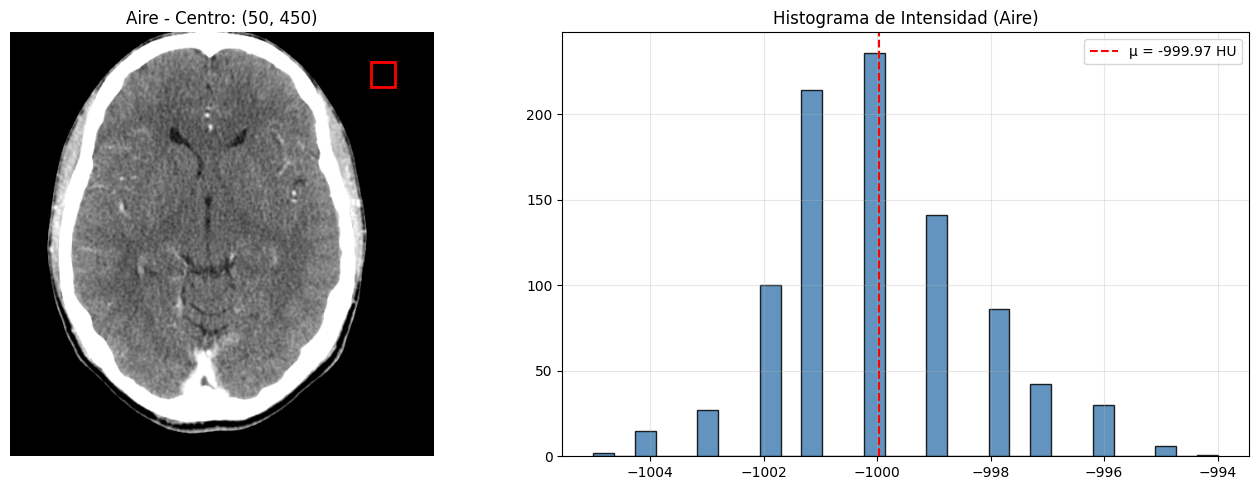

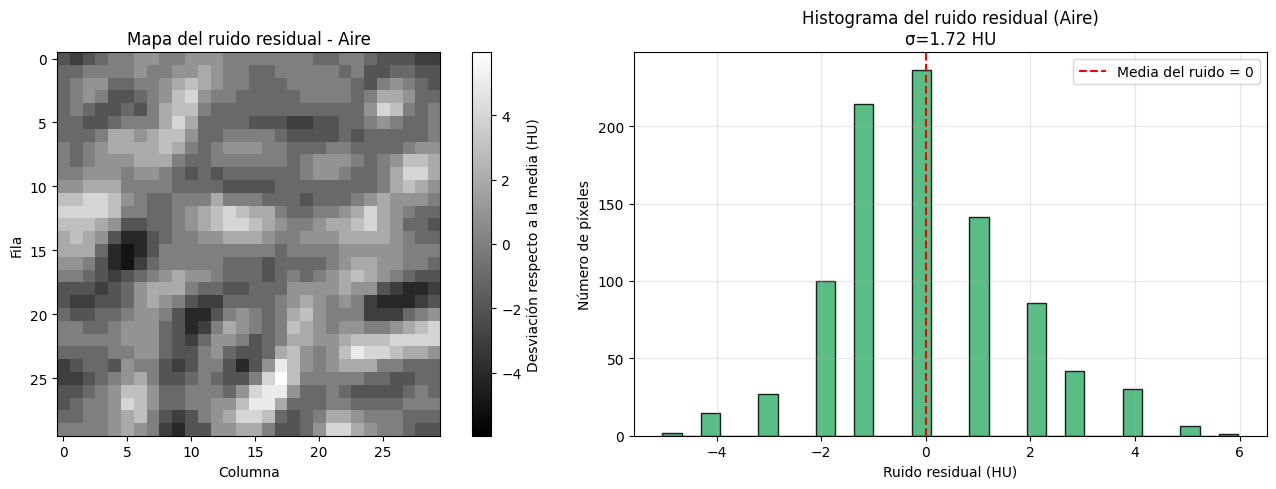

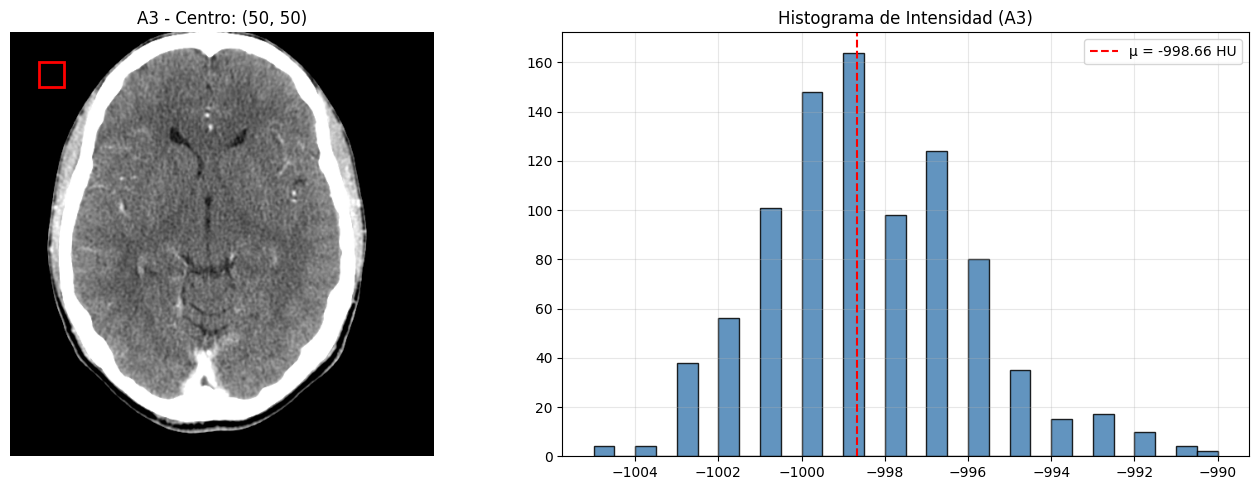

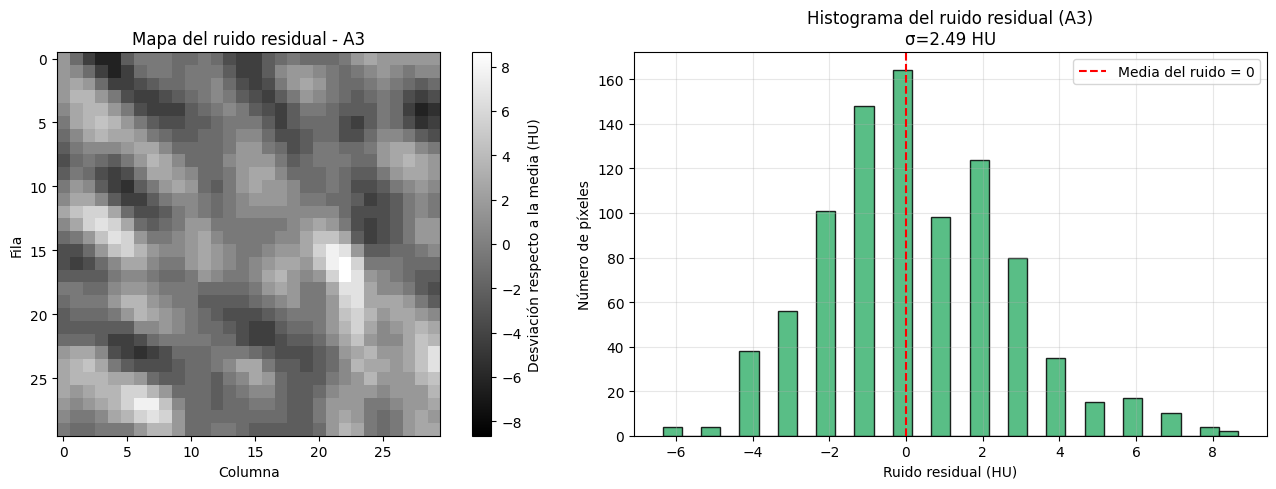

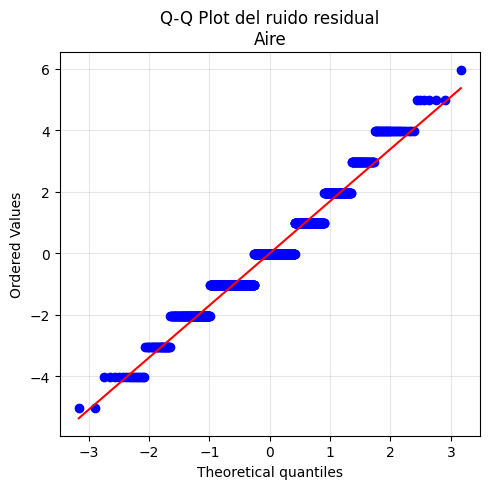

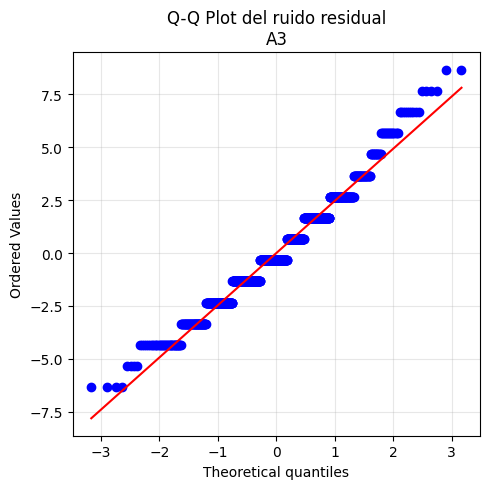


DIAGNÓSTICO SINTETIZADO DEL RUIDO

[Aire]
  • Factor Fano D = 0.123808
  • Veredicto: GAUSSIANO de reconstrucción (post-FBP)
  • Correlación Espacial: H=0.787, V=0.747

[A3]
  • Factor Fano D = 0.244513
  • Veredicto: GAUSSIANO de reconstrucción (post-FBP)
  • Correlación Espacial: H=0.821, V=0.824


In [53]:
# ============================================================
# PIPELINE DE EJECUCIÓN Y DIAGNÓSTICO DE RUIDO EN ROIs
# ============================================================

# Definimos las coordenadas de las ROIs a evaluar
rois = {
    "Aire": (50, 450),
    "A3": (50, 50)
}

# Cargamos los datos de la imagen usando el path unificado
ds, hu_array, pixel_array_crudo = cargar_dicom_hu("imagenes/tomografia craneo/Series 500 [CT - ANGIOGRAFÍA CRANEAL]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.688.0.dcm")


resultados_ruido = []
datos_rois = {}
datos_ruido = {}

# Procesamiento estadístico de cada ROI
for nombre, centro in rois.items():
    roi_hu = extraer_roi(hu_array, centro, mitad_lado=15)
    roi_cruda = extraer_roi(pixel_array_crudo, centro, mitad_lado=15)

    ruido, resultado = analizar_ruido(roi_hu, roi_cruda, nombre)

    resultados_ruido.append(resultado)
    datos_rois[nombre] = roi_hu
    datos_ruido[nombre] = ruido

# 1. Impresión de Reporte Estadístico en Consola
for resultado in resultados_ruido:
    imprimir_resultados_ruido(resultado)

# 2. Visualización Gráfica (Histograma, ROI y Ruido Residual)
for nombre in rois:
    visualizar_roi_y_ruido(
        hu_array, datos_rois[nombre], datos_ruido[nombre],
        rois[nombre], nombre=nombre, mitad_lado=15
    )

# 3. Gráficas de Probabilidad Normal (Q-Q Plots)
for nombre in rois:
    mostrar_qqplot_ruido(datos_ruido[nombre], nombre)

# 4. Diagnóstico Final Integrado
diagnostico_final_ruido(resultados_ruido)

## Filtrado Espacial: Convolución

A continuación, se define un motor de convolución a bajo nivel utilizando únicamente ciclos `for` y listas de Python. Esto permite comprender cómo se aplican los filtros (kernels) sobre las imágenes DICOM (o sus ROIs extraídas) controlando explícitamente el tratamiento de los bordes.

In [54]:
def _indice_borde(i, n, modo):
    """Índice válido (0..n-1) cuando i se sale de la imagen."""
    if 0 <= i < n:
        return i
    if modo == "replicar":              # repite el píxel del borde
        return 0 if i < 0 else n - 1
    if modo == "reflejar":              # espejo:  ... c b a | a b c ...
        while i < 0 or i >= n:
            if i < 0:
                i = -i - 1
            if i >= n:
                i = 2 * n - 1 - i
        return i
    raise ValueError("modo debe ser 'replicar', 'reflejar' o 'ceros'")

def _rellenar_bordes(img, p, modo):
    """Agrega p filas/columnas alrededor (img es lista de listas). Hecho con for."""
    H, W = len(img), len(img[0])
    nueva = []
    for i in range(-p, H + p):
        fila = []
        for j in range(-p, W + p):
            if modo == "ceros":
                fila.append(img[i][j] if (0 <= i < H and 0 <= j < W) else 0.0)
            else:
                fila.append(img[_indice_borde(i, H, modo)][_indice_borde(j, W, modo)])
        nueva.append(fila)
    return nueva

def tamano_resultante(alto, ancho, k, recuperar_bordes=False):
    if recuperar_bordes:
        return alto, ancho
    p = k // 2
    return alto - 2 * p, ancho - 2 * p

def convolucion(imagen, kernel, recuperar_bordes=False, modo_borde="replicar", voltear_kernel=False):
    """
    Convolución.
    imagen           : matriz 2D.   kernel: matriz cuadrada de tamaño impar.
    recuperar_bordes : False -> salida más pequeña | True -> padding y salida del mismo tamaño.
    modo_borde       : 'replicar', 'reflejar' o 'ceros' (solo si recuperar_bordes=True).
    Devuelve una imagen NUEVA (float64). No modifica la original.
    """
    imagen = np.asarray(imagen); kernel = np.asarray(kernel, dtype=float)
    if imagen.ndim != 2:
        raise ValueError("La imagen debe ser 2D")
    if kernel.ndim != 2 or kernel.shape[0] != kernel.shape[1]:
        raise ValueError("El kernel debe ser cuadrado")
    k = kernel.shape[0]
    if k % 2 == 0:
        raise ValueError("El kernel debe tener un tamaño impar")
    p = k // 2
    if voltear_kernel:
        kernel = kernel[::-1, ::-1]

    img = imagen.astype(float).tolist()            # copia independiente
    ker = kernel.tolist()
    if recuperar_bordes:
        img = _rellenar_bordes(img, p, modo_borde)
    H, W = len(img), len(img[0])
    alto_out, ancho_out = H - 2 * p, W - 2 * p
    if alto_out <= 0 or ancho_out <= 0:
        raise ValueError("El kernel es demasiado grande para esta imagen")

    salida = [[0.0] * ancho_out for _ in range(alto_out)]
    for i in range(alto_out):
        for j in range(ancho_out):
            suma = 0.0
            for u in range(k):
                for v in range(k):
                    suma += ker[u][v] * img[i + u][j + v]
            salida[i][j] = suma
    return np.array(salida)

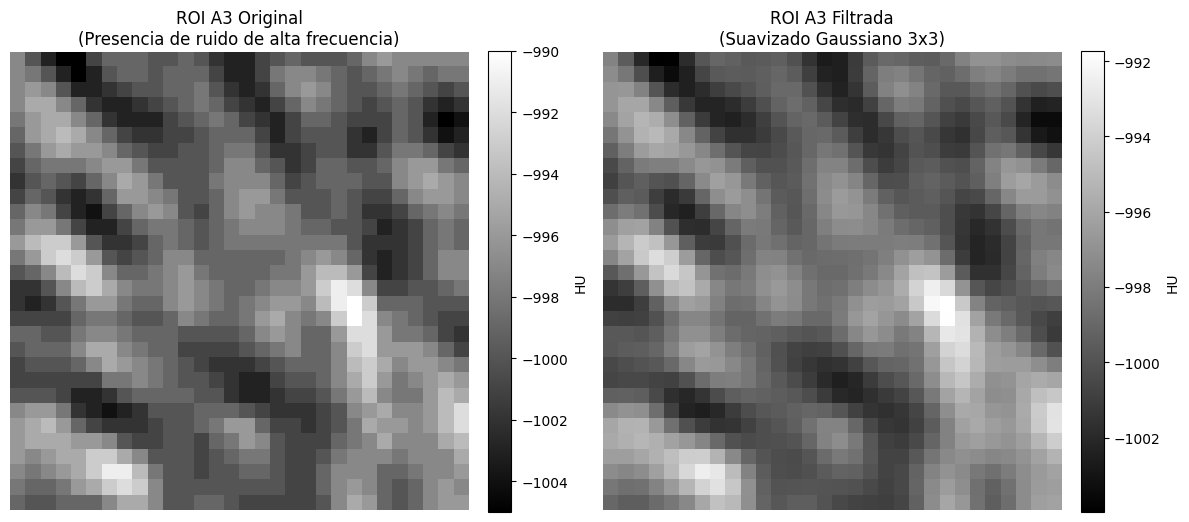

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir el kernel de 3x3 de acuerdo con los pesos proporcionados
kernel_gaussianoSNM = np.array([
    [0.058550, 0.096532, 0.058550],
    [0.096532, 0.159155, 0.096532],
    [0.058550, 0.096532, 0.058550]
])
kernel_gaussiano = np.array([
    [0.075115, 0.123843, 0.075115],
    [0.123843, 0.204167, 0.123843],
    [0.075115, 0.123843, 0.075115]
])

# Normalizar el kernel para asegurar que la ganancia sea unitaria y mantener la escala de grises original
kernel_gaussiano = kernel_gaussiano / np.sum(kernel_gaussiano)

# 2. Extraer la ROI de A3 que tenemos en memoria (con .copy() para evitar mutaciones)
roi_a3 = datos_rois["A3"].copy()

# 3. Aplicar la convolución recuperando bordes mediante replicación
roi_filtrada = convolucion(
    imagen=roi_a3,
    kernel=kernel_gaussiano,
    recuperar_bordes=True,
    modo_borde="replicar"
)

# 4. Visualización comparativa de los resultados
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# ROI original
im0 = axes[0].imshow(roi_a3, cmap="gray")
axes[0].set_title("ROI A3 Original\n(Presencia de ruido de alta frecuencia)")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="HU")

# ROI filtrada
im1 = axes[1].imshow(roi_filtrada, cmap="gray")
axes[1].set_title("ROI A3 Filtrada\n(Suavizado Gaussiano 3x3)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="HU")

plt.tight_layout()
plt.show()